# Season-Best Replication: Predicting the Big West Championships

This notebook replicates the performance-list approach used by meet calculators such as MeetScorer:

1. Take every athlete's best **outdoor** regular-season mark in each Big West event.
2. Sort the marks from best to worst in each event.
3. Give places 1–8 the championship points (10, 8, 6, 5, 4, 3, 2, 1).
4. Add up points by team and compare with the actual championship results.

The goal is to see whether this method is accurate enough to help value recruits.


In [25]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

import re

REG_PATH = "../data/processed/regular_season.csv"
BW_PATH = "../data/processed/bigwest_2019_2026_results.csv"
OUT = Path("out"); OUT.mkdir(exist_ok=True)
FIG = Path("figures"); FIG.mkdir(exist_ok=True)

POINTS = [10, 8, 6, 5, 4, 3, 2, 1]
SEASONS = [2019, 2021, 2022, 2023, 2024, 2025, 2026]     # no championship in 2020
GROUP_ORDER = ["sprint", "distance", "horizontal", "vertical", "throw", "multi", "relay"]

# plot style
BLUE, ORANGE, GRAY, INK, INK2 = "#2a78d6", "#eb6834", "#8a8984", "#0b0b0b", "#52514e"
plt.rcParams.update({"font.size": 10, "axes.edgecolor": "#c9c8c3", "axes.labelcolor": INK2,
                     "xtick.color": INK2, "ytick.color": INK2, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.color": "#ecebe7",
                     "axes.axisbelow": True, "figure.dpi": 110, "savefig.bbox": "tight", "savefig.dpi": 150})
pd.set_option("display.width", 160)

## 1. Data cleaning

Both files need the same cleaning before they can be compared:

1. **Event codes:** the championship file uses full names ("Men's 100 Meters"); the regular-season file uses codes ("100"). Everything is converted to codes.
2. **Gender:** "men"/"women" becomes "M"/"W".
3. **Team names:** uppercased, and the same school under different names is merged (e.g. "Cal State Northridge" and "Cal St. Northridge" become "CSUN").
4. **Athlete IDs:** made identical in both files (`12345`, `12345.0` and `" 12345"` all become `"12345"`).
5. **Relays:** each relay becomes one "athlete" per team, e.g. `"UC SAN DIEGO|4x100"`.
6. **Status codes:** DNF, DQ, NM, FOUL, NH become **FAILED**; DNS and SCR become **DID_NOT_COMPETE**; parseable marks are **VALID**.
7. **Marks:** converted to numbers: seconds for running events, meters for field events, points for multis.
8. **Performance scale `p`:** `log(mark)` for field and multi events, `-log(time)` for running events, so **higher is always better** and differences read as percentages (0.02 = 2%).
9. **Dates and seasons:** multi-day meets use their last day; August-December meets count toward the next spring's season.
10. **Indoor vs outdoor:** each meet is labeled from its name, its events and its month (section 1.7).

### 1.1 Event definitions and lookup tables

In [26]:
ALIASES = {"10,000": "10000", "2 Mile": "2Mile"}
RELAYS = {"4x100", "4x400", "4x440y", "4x200", "4x800", "DMR", "SMR"}
MULTIS = {"Dec", "Hep", "Pent"}
FIELD = {"LJ", "TJ", "HJ", "PV", "SP", "DT", "HT", "JT", "WT"}
WIND_EVENTS = {"100", "200", "100H", "110H", "LJ", "TJ"}      # events where wind > 2.0 m/s is wind-aided

# the same school under different names (after uppercasing)
TEAM_ALIASES = {"CAL ST. NORTHRIDGE": "CSUN", "CAL STATE NORTHRIDGE": "CSUN",
                "CAL STATE FULLERTON": "CAL ST. FULLERTON", "LONG BEACH STATE": "LONG BEACH ST.",
                "HAWAI'I": "HAWAII", "HAWAIʻI": "HAWAII"}

# result codes -> status
STATUS_MAP = {"DNS": "DID_NOT_COMPETE", "SCR": "DID_NOT_COMPETE",
              "DQ": "FAILED", "FS": "FAILED", "DNF": "FAILED", "NH": "FAILED", "NM": "FAILED",
              "FOUL": "FAILED", "NP": "FAILED", "ND": "FAILED", "NT": "MISSING"}
# scraped codes can be doubled ("FOULNM", "NHNH"): use the first code in the string
CODE_RE = r"^(" + "|".join(sorted(STATUS_MAP, key=len, reverse=True)) + r")"

# championship event names (without "Men's"/"Women's") -> codes
BW_NAME_MAP = {
    "100 Meters": "100", "200 Meters": "200", "400 Meters": "400", "800 Meters": "800",
    "1500 Meters": "1500", "5000 Meters": "5000", "10,000 Meters": "10000",
    "100 Hurdles": "100H", "110 Hurdles": "110H", "400 Hurdles": "400H",
    "3000 Steeplechase": "3000S", "4 x 100 Relay": "4x100", "4 x 400 Relay": "4x400",
    "High Jump": "HJ", "Pole Vault": "PV", "Long Jump": "LJ", "Triple Jump": "TJ",
    "Shot Put": "SP", "Discus": "DT", "Hammer": "HT", "Javelin": "JT",
    "Decathlon": "Dec", "Heptathlon": "Hep",
}
BW_LOWER = {k.lower(): v for k, v in BW_NAME_MAP.items()}


def higher_is_better(event):
    """Field and multi events: bigger mark is better. Running events and relays: smaller is better."""
    return event in FIELD or event in MULTIS


def event_group(event):
    """Event group used for summaries."""
    if event in RELAYS: return "relay"
    if event in MULTIS: return "multi"
    if event in {"HJ", "PV"}: return "vertical"
    if event in {"LJ", "TJ"}: return "horizontal"
    if event in {"SP", "DT", "HT", "JT", "WT"}: return "throw"
    if event in {"55", "60", "100", "200", "300", "400", "60H", "100H", "110H", "300H", "400H"}: return "sprint"
    return "distance"

### 1.2 Parsing marks and dates

In [27]:
def parse_mark(raw):
    """
    One raw mark string -> number in natural units.
      "10.52" -> 10.52 s      "1:52.31" -> 112.31 s     "6.45m" -> 6.45 m
      "21-04.5" -> 6.52 m (feet-inches)                 "5,432" -> 5432 points
    Returns NaN if it can't be parsed (status codes like "DNF" are handled separately).
    """
    if raw is None or (isinstance(raw, float) and np.isnan(raw)):
        return np.nan
    metric = re.match(r"^\s*(\d+(?:\.\d+)?)\s*m(?![a-z])", str(raw), flags=re.IGNORECASE)
    if metric:                                                    # '14.21m46\' 7.5"' -> 14.21
        return float(metric.group(1))
    s = re.sub(r"[A-Za-z\"]+$", "", str(raw).strip()).strip()   # drop trailing 'm', 'w', 'h', ...
    s = s.replace(",", "")
    ft_in = re.match(r"^(\d+)\s*[-']\s*(\d+(?:\.\d+)?)$", s)
    if ft_in:
        return (float(ft_in.group(1)) * 12 + float(ft_in.group(2))) * 0.0254
    if ":" in s:
        try:
            parts = [float(x) for x in s.split(":")]
        except ValueError:
            return np.nan
        return sum(v * 60 ** (len(parts) - 1 - i) for i, v in enumerate(parts))
    try:
        return float(s)
    except ValueError:
        return np.nan


def parse_meet_dates(date):
    """
    Meet date strings -> Timestamps, keeping the LAST day of multi-day meets:
      "Mar 31-Apr 1, 2023" -> Apr 1, 2023      "Apr 10-11, 2025" -> Apr 11, 2025
    """
    s = date.astype(str).str.strip()
    s = s.str.replace(r"^[A-Za-z]{3,9}\.?\s+\d{1,2}\s*-\s*(?=[A-Za-z]{3,9}\.?\s+\d{1,2},\s*\d{4}$)", "", regex=True)
    s = s.str.replace(r"^([A-Za-z]{3,9}\.?)\s+\d{1,2}\s*-\s*(\d{1,2}),\s*(\d{4})$", r"\1 \2, \3", regex=True)
    return pd.to_datetime(s, errors="coerce", format="mixed")


# quick checks
for raw in ["10.52", "1:52.31", "6.45m", "21-04.5", "5,432", "10.31w", "DNF"]:
    print(f"{raw:>8} -> {parse_mark(raw):.2f}")
print(parse_meet_dates(pd.Series(["Mar 31-Apr 1, 2023", "Apr 10-11, 2025", "Apr 9, 2022"])).dt.date.tolist())

   10.52 -> 10.52
 1:52.31 -> 112.31
   6.45m -> 6.45
 21-04.5 -> 6.52
   5,432 -> 5432.00
  10.31w -> 10.31
     DNF -> nan
[datetime.date(2023, 4, 1), datetime.date(2025, 4, 11), datetime.date(2022, 4, 9)]


### 1.3 Shared cleaning for both files

In [28]:
def clean(df, multi_min_frac=0.6):
    """Steps 2-8 above. Adds value (parsed mark), status and p."""
    df = df.copy()
    df["event"] = df["event"].astype(str).str.strip().replace(ALIASES)
    df["gender"] = df["gender"].astype(str).str.strip().str.upper().str[0].replace({"F": "W"})
    df["team"] = (df["team"].astype(str).str.strip().str.upper()
                  .str.replace(r"\s+", " ", regex=True).replace(TEAM_ALIASES))
    aid = df["athlete_id"].astype("string").str.strip().str.replace(r"\.0+$", "", regex=True)
    df["athlete_id"] = aid.fillna(df["athlete_name"].astype("string").str.strip())

    # relays: one "athlete" per team relay
    rel = df["event"].isin(RELAYS)
    df.loc[rel, "athlete_id"] = df.loc[rel, "team"] + "|" + df.loc[rel, "event"]
    df.loc[rel, "athlete_name"] = df.loc[rel, "team"] + " " + df.loc[rel, "event"]

    # status codes, then parse the rest
    up = df["mark"].astype(str).str.strip().str.upper()
    status = up.map(STATUS_MAP).fillna(up.str.extract(CODE_RE, expand=False).map(STATUS_MAP))
    df["value"] = [parse_mark(m) if pd.isna(s) else np.nan for m, s in zip(df["mark"], status)]
    ok = df["value"].notna() & (df["value"] > 0)
    df["status"] = status.where(status.notna(), np.where(ok, "VALID", "MISSING"))

    # unfinished multis: far below the event median -> FAILED
    multi = df["event"].isin(MULTIS) & (df["status"] == "VALID")
    med = df[multi].groupby(["gender", "event"])["value"].transform("median")
    df.loc[med.index[df.loc[med.index, "value"] < multi_min_frac * med], "status"] = "FAILED"

    # performance scale: higher is always better
    hib = df["event"].map(higher_is_better)
    df["p"] = np.where(df["status"] == "VALID",
                       np.where(hib, np.log(df["value"]), -np.log(df["value"])), np.nan)
    return df

### 1.4 Regular-season file

In [29]:
raw_reg = pd.read_csv(REG_PATH)
print("raw shape:", raw_reg.shape)

date = raw_reg["meet_start_date"].astype("string").fillna(raw_reg["meet_date"].astype("string"))
raw_reg["date"] = parse_meet_dates(date)
# August-December meets count toward the next spring's season
raw_reg["season"] = raw_reg["date"].dt.year + (raw_reg["date"].dt.month >= 8).astype(int)
print("rows with no parseable date (dropped):", raw_reg["date"].isna().sum())

reg = clean(raw_reg.dropna(subset=["date"]))
reg["status"].value_counts()

raw shape: (57300, 17)
rows with no parseable date (dropped): 0


status
VALID              54926
FAILED              2143
DID_NOT_COMPETE      192
MISSING               39
Name: count, dtype: int64

### 1.5 Championship file

In [30]:
raw_bw = pd.read_csv(BW_PATH)
print("raw shape:", raw_bw.shape)

def bw_event_code(name):
    s = re.sub(r"^(men|women)[’']s\s+", "", str(name).strip(), flags=re.IGNORECASE)
    s = re.sub(r"\s+", " ", s)
    return BW_LOWER.get(s.lower(), s)

raw_bw["event"] = raw_bw["event"].map(bw_event_code)
print("unmapped event names:", sorted(set(raw_bw["event"]) - set(BW_NAME_MAP.values())) or "none")
raw_bw["season"] = raw_bw["meet_year"].astype(int)
raw_bw["points"] = pd.to_numeric(raw_bw["points"], errors="coerce").fillna(0)

bw = clean(raw_bw)
bw["group"] = bw["event"].map(event_group)
bw["status"].value_counts()

raw shape: (5257, 14)
unmapped event names: none


status
VALID              5047
FAILED              204
DID_NOT_COMPETE       6
Name: count, dtype: int64

### 1.6 Checks

- Every athlete appears at most once per event per championship (final place only).
- Athlete IDs match between the two files.
- Profile date for each season: the day after the last regular-season meet. Only marks before it are used.

In [31]:
print("max rows per athlete-event-season:", bw.groupby(["season", "gender", "event", "athlete_id"]).size().max())

ind = bw[~bw["event"].isin(RELAYS)]
matched = ind["athlete_id"].isin(set(reg["athlete_id"]))
print(f"championship athletes found in the regular-season file: {matched.mean():.1%}")

last = reg.groupby("season")["date"].max()
cdates = {s: last[s] + pd.Timedelta(days=1) for s in SEASONS if s in last.index}
bw_events = {g: set(grp["event"]) for g, grp in bw.groupby("gender")}
print("profile dates:", {s: str(d.date()) for s, d in cdates.items()})
print("events per gender:", {g: len(e) for g, e in bw_events.items()})

max rows per athlete-event-season: 1
championship athletes found in the regular-season file: 100.0%
profile dates: {2019: '2019-05-04', 2021: '2021-05-15', 2022: '2022-05-14', 2023: '2023-05-13', 2024: '2024-05-10', 2025: '2025-05-10', 2026: '2026-05-09'}
events per gender: {'M': 21, 'W': 21}


### 1.7 Indoor vs outdoor marks

The season-best lists use **outdoor marks only**, but the file has no indoor/outdoor column. It reads from the `meet_venue csv` for this

In [ ]:
venues = pd.read_csv("../data/processed/meet_venues.csv")          # meet_name, meet_date, venue, note
MEET_VENUE = dict(zip(zip(venues["meet_name"], venues["meet_date"]), venues["venue"]))
print(len(MEET_VENUE), "meets:", venues["venue"].value_counts().to_dict())

keys = list(zip(reg["meet_name"], reg["date"].dt.strftime("%Y-%m-%d")))
missing = sorted(set(k for k in keys if k not in MEET_VENUE))
if missing:
    raise ValueError(f"{len(missing)} meets are not in meet_venues.csv: {missing[:10]}")
reg["venue"] = [MEET_VENUE[k] for k in keys]
reg["indoor"] = reg["venue"].eq("indoor")
print(f"marks labeled indoor: {reg['indoor'].mean():.1%}")

437 meets: {'outdoor': 316, 'indoor': 121}
marks labeled indoor: 18.9%


Share of marks labeled indoor by month. January is all indoor, February is mixed, and March and later are almost all outdoor (except the indoor championships):

In [33]:
reg.assign(month=reg["date"].dt.month).groupby("month")["indoor"].mean().round(3).rename("share_indoor")

month
1    1.000
2    0.888
3    0.025
4    0.000
5    0.000
Name: share_indoor, dtype: float64

## 2. Exploratory data analysis

### 2.1 Data overview

In [34]:
overview = pd.DataFrame({
    "reg_marks": reg.groupby("season").size(),
    "reg_outdoor_valid": reg[(reg["status"] == "VALID") & ~reg["indoor"]].groupby("season").size(),
    "reg_athletes": reg.groupby("season")["athlete_id"].nunique(),
    "bw_results": bw.groupby("season").size(),
    "bw_teams": bw.groupby("season")["team"].nunique(),
    "bw_no_valid_mark": bw[bw["status"] != "VALID"].groupby("season").size(),
}).fillna(0).astype(int)
overview

,reg_marks,reg_outdoor_valid,reg_athletes,bw_results,bw_teams,bw_no_valid_mark
season,,,,,,
2019,6888,5463,672,678,9,27
2021,4813,4628,653,642,10,17
2022,8825,7146,806,707,10,37
2023,9187,6872,784,739,10,17
2024,9051,6535,862,746,10,27
2025,9673,7323,883,892,11,44
2026,8863,6601,827,853,11,41


**Which schools competed each year.** UC San Diego has regular-season marks from 2021 but appears in the championship results only from 2025; CSU Bakersfield is missing in 2019. Each season's predicted field is therefore limited to the schools at that year's championship.

In [35]:
pd.DataFrame({
    "regular_season": reg.groupby(["team", "season"]).size().unstack().notna().sum(axis=1),
    "championship": bw.groupby(["team", "season"]).size().unstack().notna().sum(axis=1),
}).rename_axis("seasons with data")

,regular_season,championship
seasons with data,,
CAL POLY,7,7
CAL ST. FULLERTON,7,7
CSU BAKERSFIELD,6,6
CSUN,7,7
HAWAII,7,7
LONG BEACH ST.,7,7
UC DAVIS,7,7
UC IRVINE,7,7
UC RIVERSIDE,7,7


In [36]:
bw.groupby(["season", "team"]).size().unstack(0).fillna(0).astype(int)

season,2019,2021,2022,2023,2024,2025,2026
team,,,,,,,
CAL POLY,91,103,96,93,97,96,91
CAL ST. FULLERTON,95,116,107,103,100,114,112
CSU BAKERSFIELD,0,27,39,35,32,34,41
CSUN,51,28,46,69,79,73,84
HAWAII,30,26,35,47,47,47,43
LONG BEACH ST.,110,77,97,101,92,107,74
UC DAVIS,101,69,67,57,67,67,61
UC IRVINE,50,63,65,79,93,91,95
UC RIVERSIDE,60,32,58,65,67,71,66


### 2.2 Building the season-best lists

In [37]:
def outdoor_marks(reg, season, as_of, bw_events, legal_only=False, include_indoor=False):
    """Valid regular-season marks in Big West events for one season, before as_of."""
    r = reg[(reg["season"] == season) & (reg["status"] == "VALID") & (reg["date"] < as_of)]
    if not include_indoor:
        r = r[~r["indoor"]]                                    # outdoor meets only (section 1.7)
    r = r[[e in bw_events.get(g, set()) for g, e in zip(r["gender"], r["event"])]]
    if legal_only:                                            # drop wind-aided marks (wind > 2.0 m/s)
        w = pd.to_numeric(r["wind"], errors="coerce")
        r = r[~(r["event"].isin(WIND_EVENTS) & (w > 2.0))]
    return r


def season_best_lists(marks):
    """One row per (gender, event, athlete): season best on the p scale and in natural units."""
    idx = marks.groupby(["gender", "event", "athlete_id"])["p"].idxmax()
    sb = marks.loc[idx, ["gender", "event", "athlete_id", "athlete_name", "team", "p", "value", "date"]]
    return sb.rename(columns={"p": "sb_p", "value": "sb_mark", "date": "sb_date"}).reset_index(drop=True)


# example: the 2026 women's 1500 m list
sb26 = season_best_lists(outdoor_marks(reg, 2026, cdates[2026], bw_events))
sb26[(sb26["gender"] == "W") & (sb26["event"] == "1500")].sort_values("sb_p", ascending=False).head(10)

,gender,event,athlete_id,athlete_name,team,sb_p,sb_mark,sb_date
1034,W,1500,9199325,Emma Hadley,UC IRVINE,-5.552843,257.97,2026-05-01
933,W,1500,7908093,Sylvana Northrop,UC SAN DIEGO,-5.560951,260.07,2026-04-16
967,W,1500,8616365,Kaia Schmidt,UC IRVINE,-5.564290,260.94,2026-05-01
946,W,1500,8269647,Isabella Smith,CAL ST. FULLERTON,-5.569527,262.31,2026-04-16
999,W,1500,8907392,Natalyn Membreno,CAL ST. FULLERTON,-5.580748,265.27,2026-03-27
996,W,1500,8906581,Nicole Bridges,CAL POLY,-5.589007,267.47,2026-04-16
973,W,1500,8895109,Lucy Milliner,HAWAII,-5.591808,268.22,2026-04-16
1009,W,1500,8996743,Dasha LeFaivre,UC SAN DIEGO,-5.591882,268.24,2026-04-03
980,W,1500,8897163,Dasha LeFaivre,UC SAN DIEGO,-5.591882,268.24,2026-04-03
995,W,1500,8906580,Ella Echsner,CAL POLY,-5.592180,268.32,2026-04-16


### 2.3 Coverage: did championship entrants have an outdoor season best?

The method can only rank athletes with an outdoor mark in the event. Entrants without one are invisible to it.

In [38]:
rows = []
for s in SEASONS:
    allm = outdoor_marks(reg, s, cdates[s], bw_events, include_indoor=True)
    outd = allm[~allm["indoor"]]
    k_out = set(zip(outd["gender"], outd["event"], outd["athlete_id"]))
    k_all = set(zip(allm["gender"], allm["event"], allm["athlete_id"]))
    b = bw[bw["season"] == s].copy()
    key = list(zip(b["gender"], b["event"], b["athlete_id"]))
    b["coverage"] = np.where([k in k_out for k in key], "outdoor SB",
                             np.where([k in k_all for k in key], "indoor only", "no mark in event"))
    rows.append(b)
cov = pd.concat(rows)

print("Share of entrants:")
display(pd.crosstab(cov["season"], cov["coverage"], normalize="index").round(3))
print("Scorers (points > 0):")
display(pd.crosstab(cov.loc[cov["points"] > 0, "season"], cov.loc[cov["points"] > 0, "coverage"]))
print("Points scored by athletes with no outdoor season best:")
cov[(cov["coverage"] != "outdoor SB")].groupby("season")["points"].sum()

Share of entrants:


coverage,indoor only,no mark in event,outdoor SB
season,,,
2019,0.001,0.068,0.931
2021,0.000,0.081,0.919
2022,0.000,0.047,0.953
2023,0.004,0.046,0.950
2024,0.003,0.051,0.946
2025,0.003,0.041,0.955
2026,0.004,0.060,0.937


Scorers (points > 0):


coverage,indoor only,no mark in event,outdoor SB
season,,,
2019,1,17,317
2021,0,24,305
2022,0,6,326
2023,2,16,319
2024,1,14,322
2025,1,13,320
2026,2,19,315


Points scored by athletes with no outdoor season best:


season
2019     98.0
2021    103.0
2022     31.0
2023     85.0
2024     70.0
2025     66.0
2026    103.0
Name: points, dtype: float64

### 2.4 Field size

Without entry lists, the "everyone" field includes every athlete with a mark in the event. How much bigger is that than the real field?

In [39]:
fs = []
for s in SEASONS:
    bws = bw[bw["season"] == s]
    sb = season_best_lists(outdoor_marks(reg, s, cdates[s], bw_events))
    n_every = sb[sb["team"].isin(set(bws["team"]))].groupby(["gender", "event"]).size()
    n_ent = bws.groupby(["gender", "event"]).size()
    fs.append(pd.DataFrame({"season": s, "list_size": n_every, "entrants": n_ent}).reset_index())
fs = pd.concat(fs, ignore_index=True)
fs["group"] = fs["event"].map(event_group)
fs["ratio"] = fs["list_size"] / fs["entrants"]
fs.groupby("group")[["list_size", "entrants", "ratio"]].median().reindex(GROUP_ORDER).round(2)

,list_size,entrants,ratio
group,,,
sprint,50.5,18.5,2.56
distance,53.0,19.5,1.80
horizontal,30.5,18.0,1.71
vertical,24.0,14.0,1.76
throw,34.0,17.0,1.90
multi,9.5,10.5,1.00
relay,9.0,9.0,1.00


### 2.5 Season best vs championship mark

For entrants with an outdoor season best: how did their championship mark compare? `diff_pct > 0` means they beat their season best. Results more than 50% below the season best are treated as failures and dropped (same rule as the main model).

In [40]:
sbc = []
for s in SEASONS:
    sb = season_best_lists(outdoor_marks(reg, s, cdates[s], bw_events))
    a = bw[(bw["season"] == s) & (bw["status"] == "VALID")][["gender", "event", "athlete_id", "p"]]
    sbc.append(a.merge(sb, on=["gender", "event", "athlete_id"]).assign(season=s))
sbc = pd.concat(sbc, ignore_index=True)
sbc["group"] = sbc["event"].map(event_group)
sbc["diff_pct"] = 100 * (sbc["p"] - sbc["sb_p"])
sbc = sbc[sbc["diff_pct"] > 100 * np.log(0.5)]

def summarize(x):
    return pd.Series({"n": len(x), "median": x.median(), "mean": x.mean(),
                      "beat_sb": (x > 0).mean(), "within_1pct": (x.abs() <= 1).mean()})

sb_tab = sbc.groupby("group")["diff_pct"].apply(summarize).unstack().reindex(GROUP_ORDER)
sb_tab.loc["all"] = summarize(sbc["diff_pct"])
sb_tab.round(3)

,n,median,mean,beat_sb,within_1pct
group,,,,,
sprint,1325.0,-0.450,-0.672,0.363,0.510
distance,1240.0,-1.646,-1.981,0.198,0.299
horizontal,488.0,-1.400,-1.694,0.279,0.262
vertical,392.0,-1.749,-1.796,0.237,0.235
throw,966.0,-2.299,-2.738,0.307,0.170
multi,126.0,2.178,3.503,0.730,0.183
relay,229.0,-0.285,-0.205,0.393,0.607
all,4766.0,-0.998,-1.496,0.301,0.334


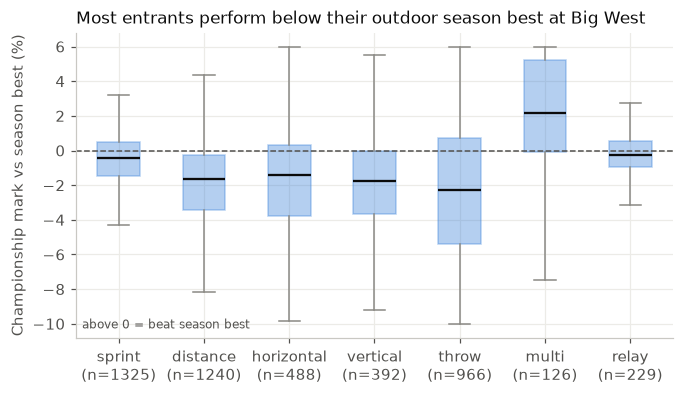

In [41]:
fig, ax = plt.subplots(figsize=(7, 3.6))
data = [sbc.loc[sbc["group"] == g, "diff_pct"].clip(-10, 6) for g in GROUP_ORDER]
bp = ax.boxplot(data, widths=0.5, patch_artist=True, showfliers=False,
                medianprops=dict(color=INK, linewidth=1.5), whiskerprops=dict(color=GRAY), capprops=dict(color=GRAY))
for p in bp["boxes"]:
    p.set(facecolor=BLUE, alpha=0.35, edgecolor=BLUE)
ax.axhline(0, color=INK2, linewidth=1, linestyle="--")
ax.set_xticks(range(1, len(GROUP_ORDER) + 1), [f"{g}\n(n={int(sb_tab.loc[g, 'n'])})" for g in GROUP_ORDER])
ax.set_ylabel("Championship mark vs season best (%)")
ax.set_title("Most entrants perform below their outdoor season best at Big West", loc="left", fontsize=11, color=INK)
ax.text(0.01, 0.03, "above 0 = beat season best", transform=ax.transAxes, color=INK2, fontsize=8)
fig.savefig(FIG / "fig_sb_vs_champ.png")
plt.show()

### 2.6 Scoring standards

Median mark needed for 1st, 3rd and 8th at Big West, 2019–2026 (seconds for running events, meters for field events, points for multis).

In [42]:
std = []
for (g, e), grp in bw[bw["status"] == "VALID"].groupby(["gender", "event"]):
    r = {"gender": g, "event": e}
    for pl in (1, 3, 8):
        v = grp.loc[grp["place"] == pl, "value"]
        r[f"place{pl}"] = round(v.median(), 2) if len(v) else np.nan
    std.append(r)
standards = pd.DataFrame(std)
standards.to_csv(OUT / "scoring_standards.csv", index=False)
standards

,gender,event,place1,place3,place8
0,M,100,10.26,10.38,11.27
1,M,10000,1845.27,1851.13,1877.49
2,M,110H,13.75,14.01,14.63
3,M,1500,224.68,228.07,231.64
4,M,200,20.85,21.01,22.02
5,M,3000S,532.25,540.92,563.39
6,M,400,46.77,47.18,48.44
7,M,400H,51.08,51.89,53.92
8,M,4x100,39.71,41.14,41.88
9,M,4x400,189.66,191.71,198.85


## 3. The season-best model

Two versions of the field, because the dataset has no entry lists:

- **Entrants:** only athletes who actually competed in that event at that year's Big West. Uses information not available before the meet, so it is the best case for the method.
- **Everyone:** every athlete with an outdoor mark in the event, from schools at that year's championship. This is the list a coach could build before the meet.

As in a meet calculator, wind-aided marks count and there is no limit on events per athlete.

In [43]:
def score_lists(sb, points=POINTS):
    """Rank each event's list from best to worst; top 8 score."""
    sb = sb.copy()
    sb["pred_place"] = sb.groupby(["gender", "event"])["sb_p"].rank(ascending=False, method="first").astype(int)
    sb["pred_pts"] = sb["pred_place"].map({i + 1: p for i, p in enumerate(points)}).fillna(0.0)
    return sb.sort_values(["gender", "event", "pred_place"]).reset_index(drop=True)


def build_field(sb, bw_season, mode):
    if mode == "entrants":
        ent = bw_season[["gender", "event", "athlete_id"]].drop_duplicates()
        return sb.merge(ent, on=["gender", "event", "athlete_id"])
    return sb[sb["team"].isin(set(bw_season["team"]))]       # everyone, from schools at the meet


def predict_season(season, mode, **kw):
    """Season-best predictions for one championship, joined to the actual results."""
    bws = bw[bw["season"] == season]
    sb = season_best_lists(outdoor_marks(reg, season, cdates[season], bw_events, **kw))
    pred = score_lists(build_field(sb, bws, mode))
    act = bws[["gender", "event", "athlete_id", "place", "points", "status", "p"]].rename(
        columns={"place": "act_place", "points": "act_pts", "p": "act_p"})
    ath = pred.merge(act, on=["gender", "event", "athlete_id"], how="outer")
    ath["team"] = ath["team"].fillna(ath["athlete_id"].map(bws.set_index("athlete_id")["team"].to_dict()))
    ath[["pred_pts", "act_pts"]] = ath[["pred_pts", "act_pts"]].fillna(0.0)
    return ath.assign(season=season)


def team_tables(ath):
    te = ath.groupby(["season", "gender", "event", "team"])[["pred_pts", "act_pts"]].sum().reset_index()
    tot = te.groupby(["season", "gender", "team"])[["pred_pts", "act_pts"]].sum().reset_index()
    tot["pred_rank"] = tot.groupby(["season", "gender"])["pred_pts"].rank(ascending=False, method="min")
    tot["act_rank"] = tot.groupby(["season", "gender"])["act_pts"].rank(ascending=False, method="min")
    return te, tot

## 4. Evaluation

Metrics per championship (season × gender):

| Metric | Meaning |
|---|---|
| `total_mae` | average absolute error in team totals (points) |
| `spearman` | rank correlation of predicted and actual team totals |
| `winner_correct` | predicted winner won |
| `te_mae` | average absolute error in a team's points in one event |
| `scorer_precision` | share of predicted top-8 athletes who scored |
| `scorer_recall` | share of actual scorers who were predicted to score |
| `place_exact`, `place_within1` | for athletes predicted and actually scoring: exact place / within one place |

In [44]:
def evaluate(ath):
    te, tot = team_tables(ath)
    rows = []
    for (s, g), t in tot.groupby(["season", "gender"]):
        a = ath[(ath["season"] == s) & (ath["gender"] == g)]
        e = te[(te["season"] == s) & (te["gender"] == g)]
        ps, as_ = a["pred_pts"] > 0, a["act_pts"] > 0
        both = a[ps & as_]
        rows.append(dict(
            season=s, gender=g, n_teams=len(t),
            total_mae=np.mean(np.abs(t["pred_pts"] - t["act_pts"])),
            spearman=spearmanr(t["pred_pts"], t["act_pts"])[0],
            winner_correct=t.loc[t["pred_pts"].idxmax(), "team"] == t.loc[t["act_pts"].idxmax(), "team"],
            rank_exact=np.mean(t["pred_rank"] == t["act_rank"]),
            te_mae=np.mean(np.abs(e["pred_pts"] - e["act_pts"])),
            scorer_precision=(ps & as_).sum() / ps.sum(),
            scorer_recall=(ps & as_).sum() / as_.sum(),
            place_exact=np.mean(both["pred_place"] == both["act_place"]),
            place_within1=np.mean(np.abs(both["pred_place"] - both["act_place"]) <= 1),
        ))
    return pd.DataFrame(rows)


def run_all(mode, **kw):
    ath = pd.concat([predict_season(s, mode, **kw) for s in SEASONS], ignore_index=True)
    return ath, evaluate(ath)


results = {}
for mode in ("entrants", "everyone"):
    ath, met = run_all(mode)
    te, tot = team_tables(ath)
    results[mode] = dict(ath=ath, met=met, te=te, tot=tot)
    ath.to_csv(OUT / f"sb_athletes_{mode}.csv", index=False)
    tot.to_csv(OUT / f"sb_team_totals_{mode}.csv", index=False)
    met.round(3).to_csv(OUT / f"sb_metrics_{mode}.csv", index=False)

results["entrants"]["met"].round(3)

,season,gender,n_teams,total_mae,spearman,winner_correct,rank_exact,te_mae,scorer_precision,scorer_recall,place_exact,place_within1
0,2019,M,8,12.000,0.910,False,0.250,2.201,0.754,0.754,0.310,0.659
1,2019,W,9,13.889,0.733,True,0.444,2.335,0.810,0.786,0.333,0.682
2,2021,M,9,7.000,0.996,True,0.889,1.978,0.814,0.779,0.354,0.685
3,2021,W,10,6.700,0.985,True,0.700,1.650,0.835,0.795,0.333,0.629
4,2022,M,9,14.000,0.912,False,0.111,1.936,0.814,0.819,0.257,0.566
5,2022,W,10,12.700,0.770,True,0.200,2.040,0.774,0.783,0.300,0.708
6,2023,M,9,9.333,0.967,False,0.556,2.119,0.816,0.796,0.241,0.541
7,2023,W,10,7.933,0.915,True,0.200,2.158,0.798,0.788,0.276,0.604
8,2024,M,9,6.000,0.983,True,0.778,2.077,0.809,0.789,0.260,0.626
9,2024,W,10,12.000,0.915,False,0.500,2.093,0.774,0.760,0.185,0.585


In [45]:
results["everyone"]["met"].round(3)

,season,gender,n_teams,total_mae,spearman,winner_correct,rank_exact,te_mae,scorer_precision,scorer_recall,place_exact,place_within1
0,2019,M,8,10.375,0.910,False,0.125,2.177,0.702,0.707,0.297,0.678
1,2019,W,9,10.889,0.867,True,0.444,2.374,0.738,0.738,0.363,0.694
2,2021,M,9,9.333,0.979,True,0.667,1.974,0.775,0.761,0.371,0.694
3,2021,W,10,7.400,0.985,True,0.700,1.782,0.792,0.759,0.286,0.619
4,2022,M,9,16.333,0.929,False,0.333,2.053,0.732,0.741,0.252,0.528
5,2022,W,10,14.700,0.721,True,0.300,1.974,0.726,0.735,0.287,0.639
6,2023,M,9,12.333,0.962,False,0.444,2.223,0.743,0.743,0.242,0.500
7,2023,W,10,8.767,0.918,True,0.300,2.036,0.750,0.741,0.294,0.627
8,2024,M,9,5.333,0.983,True,0.778,1.965,0.756,0.747,0.323,0.637
9,2024,W,10,12.450,0.927,False,0.400,2.198,0.732,0.719,0.211,0.585


**Sanity check:** with 21 events × 39 points per event, each championship has about 819 points to give out. Predicted and actual totals should match closely (a little lower where an event's list had fewer than 8 athletes, or where actual places were tied).

In [46]:
results["entrants"]["ath"].groupby(["season", "gender"])[["pred_pts", "act_pts"]].sum().T

season     2019          2021          2022          2023           2024          2025          2026       
gender        M      W      M      W      M      W      M       W      M      W      M      W      M      W
pred_pts  818.0  810.0  787.0  799.0  818.0  819.0  810.0  819.00  803.0  819.0  818.0  819.0  804.0  819.0
act_pts   817.0  816.0  814.0  815.0  817.0  817.0  818.0  818.99  817.0  819.0  818.0  818.0  818.0  819.0

### 4.1 Benchmark: last year's team totals

A simple alternative: predict each team's total with its actual total from the previous championship (2019 for 2021). Teams without a previous championship are left out.

In [47]:
def naive_last_year(bw):
    tot = bw.groupby(["season", "gender", "team"])["points"].sum().reset_index()
    order = sorted(tot["season"].unique())
    prev = dict(zip(order[1:], order[:-1]))
    rows = []
    for s in order[1:]:
        for g in ("M", "W"):
            cur = tot[(tot["season"] == s) & (tot["gender"] == g)].set_index("team")["points"]
            old = tot[(tot["season"] == prev[s]) & (tot["gender"] == g)].set_index("team")["points"].reindex(cur.index)
            k = old.notna()
            rows.append(dict(season=s, gender=g, total_mae=np.mean(np.abs(old[k] - cur[k])),
                             spearman=spearmanr(old[k], cur[k])[0], winner_correct=old[k].idxmax() == cur.idxmax()))
    return pd.DataFrame(rows)

naive = naive_last_year(bw)
naive.round(3)

,season,gender,total_mae,spearman,winner_correct
0,2021,M,36.250,0.755,False
1,2021,W,37.833,0.728,False
2,2022,M,18.222,0.895,True
3,2022,W,50.800,0.365,False
4,2023,M,25.444,0.762,True
5,2023,W,15.967,0.842,True
6,2024,M,25.444,0.850,False
7,2024,W,20.951,0.830,False
8,2025,M,16.556,0.917,True
9,2025,W,22.050,0.927,False


### 4.2 Summary table

In [48]:
def summary_col(met):
    return pd.Series({
        "Team total MAE": met["total_mae"].mean(),
        "Spearman": met["spearman"].mean(),
        "Winner correct": f"{int(met['winner_correct'].sum())} / {len(met)}",
        "Team-event MAE": met["te_mae"].mean() if "te_mae" in met else np.nan,
        "Scorer precision": met["scorer_precision"].mean() if "scorer_precision" in met else np.nan,
        "Scorer recall": met["scorer_recall"].mean() if "scorer_recall" in met else np.nan,
        "Exact place": met["place_exact"].mean() if "place_exact" in met else np.nan,
        "Place within one": met["place_within1"].mean() if "place_within1" in met else np.nan,
    })

summary = pd.DataFrame({"Entrants field": summary_col(results["entrants"]["met"]),
                        "Everyone field": summary_col(results["everyone"]["met"]),
                        "Last year's totals": summary_col(naive)})
summary.to_csv(OUT / "summary.csv")
summary.map(lambda v: round(v, 3) if isinstance(v, float) else v)

,Entrants field,Everyone field,Last year's totals
Team total MAE,10.301,11.389,26.226
Spearman,0.919,0.922,0.789
Winner correct,10 / 14,10 / 14,6 / 12
Team-event MAE,2.041,2.04,NaN
Scorer precision,0.792,0.743,NaN
Scorer recall,0.78,0.739,NaN
Exact place,0.284,0.289,NaN
Place within one,0.63,0.621,NaN


In [49]:
for mode in ("entrants", "everyone"):
    t = results[mode]["tot"]
    err = (t["pred_pts"] - t["act_pts"]).abs()
    print(f"{mode:9s} mean actual total {t['act_pts'].mean():.1f} | median abs error {err.median():.1f} | "
          f"share within 10 pts {(err <= 10).mean():.2f} | largest error {err.max():.1f}")

entrants  mean actual total 84.8 | median abs error 8.0 | share within 10 pts 0.61 | largest error 41.5
everyone  mean actual total 84.8 | median abs error 10.0 | share within 10 pts 0.52 | largest error 48.0


### 4.3 Predicted vs actual team totals

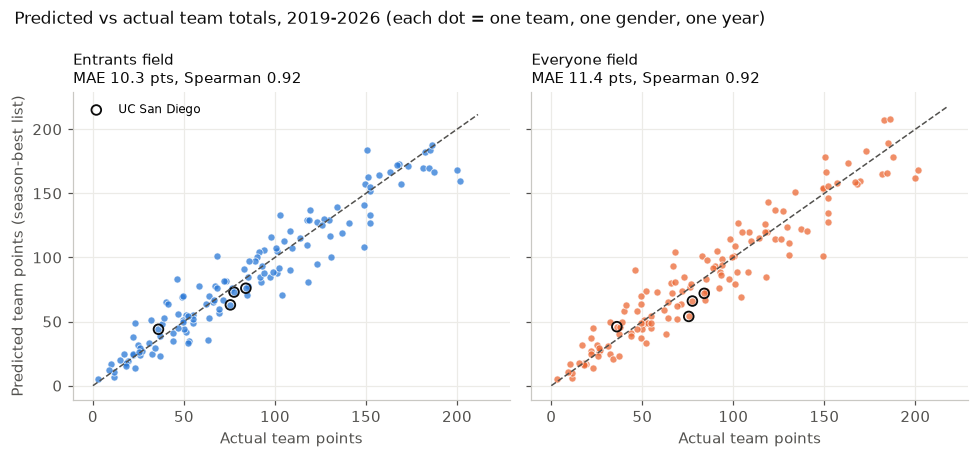

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4.2), sharex=True, sharey=True)
for ax, m, col in zip(axes, ("entrants", "everyone"), (BLUE, ORANGE)):
    t = results[m]["tot"]
    ax.scatter(t["act_pts"], t["pred_pts"], s=22, color=col, alpha=0.75, edgecolor="white", linewidth=0.6)
    u = t[t["team"] == "UC SAN DIEGO"]
    ax.scatter(u["act_pts"], u["pred_pts"], s=40, facecolor="none", edgecolor=INK, linewidth=1.2, label="UC San Diego")
    lim = [0, t[["act_pts", "pred_pts"]].max().max() + 10]
    ax.plot(lim, lim, color=INK2, linewidth=1, linestyle="--")
    met = results[m]["met"]
    ax.set_title(f"{m.capitalize()} field\nMAE {met['total_mae'].mean():.1f} pts, Spearman {met['spearman'].mean():.2f}",
                 loc="left", fontsize=10, color=INK)
    ax.set_xlabel("Actual team points")
axes[0].set_ylabel("Predicted team points (season-best list)")
axes[0].legend(frameon=False, fontsize=8, loc="upper left")
fig.suptitle("Predicted vs actual team totals, 2019-2026 (each dot = one team, one gender, one year)",
             x=0.02, ha="left", fontsize=11, color=INK)
fig.tight_layout()
fig.savefig(FIG / "fig_team_totals.png")
plt.show()

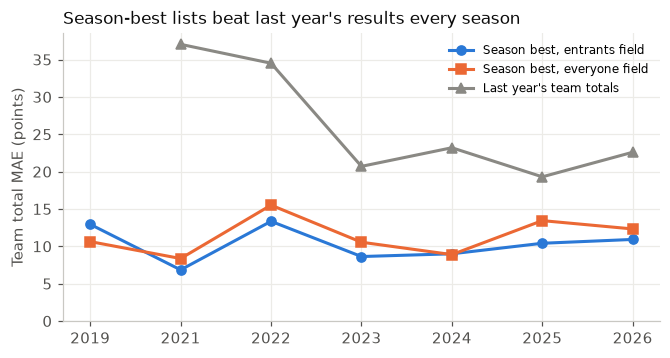

In [51]:
fig, ax = plt.subplots(figsize=(7, 3.4))
x = [str(s) for s in SEASONS]
for m, col, mk in (("entrants", BLUE, "o"), ("everyone", ORANGE, "s")):
    ax.plot(x, results[m]["met"].groupby("season")["total_mae"].mean().values, color=col, marker=mk,
            linewidth=2, label=f"Season best, {m} field")
ax.plot(x, naive.groupby("season")["total_mae"].mean().reindex(SEASONS).values, color=GRAY, marker="^",
        linewidth=2, label="Last year's team totals")
ax.set_ylabel("Team total MAE (points)")
ax.set_ylim(0, None)
ax.legend(frameon=False, fontsize=8, loc="upper right")
ax.set_title("Season-best lists beat last year's results every season", loc="left", fontsize=11, color=INK)
fig.savefig(FIG / "fig_mae_by_season.png")
plt.show()

### 4.4 Individual places

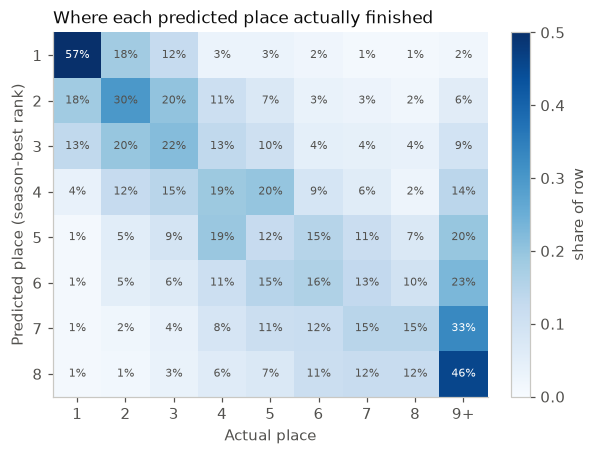

In [52]:
ent = results["entrants"]["ath"]
a = ent[(ent["pred_place"] <= 8) & ent["act_place"].notna()]
cm = pd.crosstab(a["pred_place"].astype(int), a["act_place"].clip(upper=9).astype(int), normalize="index")

fig, ax = plt.subplots(figsize=(5.6, 4.3))
im = ax.imshow(cm.values, cmap="Blues", vmin=0, vmax=0.5, aspect="auto")
ax.set_xticks(range(cm.shape[1]), [str(c) if c < 9 else "9+" for c in cm.columns])
ax.set_yticks(range(cm.shape[0]), cm.index)
ax.set_xlabel("Actual place"); ax.set_ylabel("Predicted place (season-best rank)")
ax.grid(False)
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        v = cm.values[i, j]
        ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=7, color="white" if v > 0.3 else INK2)
ax.set_title("Where each predicted place actually finished", loc="left", fontsize=11, color=INK)
fig.colorbar(im, ax=ax, fraction=0.04, label="share of row")
fig.savefig(FIG / "fig_place_confusion.png")
plt.show()

### 4.5 Accuracy by event group

In [53]:
rows = []
for m in ("entrants", "everyone"):
    te, a = results[m]["te"].copy(), results[m]["ath"].copy()
    te["group"], a["group"] = te["event"].map(event_group), a["event"].map(event_group)
    ps, as_ = a["pred_pts"] > 0, a["act_pts"] > 0
    rows.append(pd.DataFrame({
        "te_mae": (te["pred_pts"] - te["act_pts"]).abs().groupby(te["group"]).mean(),
        "scorer_recall": (ps & as_).groupby(a["group"]).sum() / as_.groupby(a["group"]).sum(),
        "scorer_precision": (ps & as_).groupby(a["group"]).sum() / ps.groupby(a["group"]).sum(),
    }).reindex(GROUP_ORDER).assign(field=m))
by_group = pd.concat(rows)
by_group.round(3)

,te_mae,scorer_recall,scorer_precision,field
group,,,,
sprint,1.780,0.813,0.800,entrants
distance,2.372,0.694,0.725,entrants
horizontal,2.293,0.763,0.763,entrants
vertical,2.272,0.756,0.790,entrants
throw,1.737,0.797,0.797,entrants
multi,3.115,0.741,0.856,entrants
relay,1.665,0.953,0.927,entrants
sprint,1.855,0.751,0.739,everyone
distance,2.411,0.624,0.639,everyone


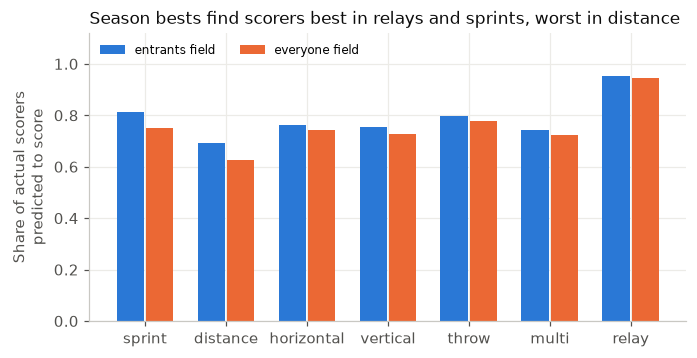

In [54]:
fig, ax = plt.subplots(figsize=(7, 3.4))
x = np.arange(len(GROUP_ORDER))
for i, (m, col) in enumerate((("entrants", BLUE), ("everyone", ORANGE))):
    v = by_group[by_group["field"] == m]["scorer_recall"].reindex(GROUP_ORDER)
    ax.bar(x + (i - 0.5) * 0.36, v.values, width=0.34, color=col, label=f"{m} field")
ax.set_xticks(x, GROUP_ORDER)
ax.set_ylim(0, 1.12)
ax.set_ylabel("Share of actual scorers\npredicted to score")
ax.legend(frameon=False, fontsize=8, loc="upper left", ncol=2)
ax.set_title("Season bests find scorers best in relays and sprints, worst in distance", loc="left", fontsize=11, color=INK)
fig.savefig(FIG / "fig_recall_by_group.png")
plt.show()

### 4.6 Entrants vs everyone

How many athletes the everyone list placed in the top 8 actually competed in that event at Big West?

In [55]:
p = results["everyone"]["ath"]
p = p[p["pred_pts"] > 0]
print(f"{p['status'].notna().mean():.1%} of the everyone list's predicted scorers competed in that event")

90.9% of the everyone list's predicted scorers competed in that event


### 4.7 Robustness

Same model, removing wind-aided marks, or adding indoor marks.

In [56]:
rob = {}
for label, kw in [("baseline", {}), ("legal wind only", dict(legal_only=True)), ("indoor included", dict(include_indoor=True))]:
    for mode in ("entrants", "everyone"):
        _, met = run_all(mode, **kw)
        rob[(label, mode)] = met[["total_mae", "spearman", "winner_correct", "te_mae", "scorer_recall", "place_exact"]].mean()
pd.DataFrame(rob).T.round(3)

total_mae  spearman  winner_correct  te_mae  scorer_recall  place_exact
baseline        entrants     10.301     0.919           0.714   2.041          0.780        0.284
                everyone     11.389     0.922           0.714   2.040          0.739        0.289
legal wind only entrants     10.724     0.915           0.643   2.080          0.780        0.286
                everyone     11.611     0.920           0.714   2.071          0.737        0.285
indoor included entrants     10.548     0.902           0.714   2.024          0.783        0.282
                everyone     11.683     0.914           0.786   2.045          0.734        0.285

### 4.8 UC San Diego

In [57]:
pd.concat([results[m]["tot"].query("team == 'UC SAN DIEGO'").assign(field=m) for m in results])

,season,gender,team,pred_pts,act_pts,pred_rank,act_rank,field
101,2025,M,UC SAN DIEGO,44.0,36.0,8.0,7.0,entrants
112,2025,W,UC SAN DIEGO,63.0,75.5,6.0,5.0,entrants
122,2026,M,UC SAN DIEGO,73.0,77.5,5.0,5.0,entrants
133,2026,W,UC SAN DIEGO,76.0,84.0,4.0,4.0,entrants
101,2025,M,UC SAN DIEGO,46.0,36.0,8.0,7.0,everyone
112,2025,W,UC SAN DIEGO,54.0,75.5,7.0,5.0,everyone
122,2026,M,UC SAN DIEGO,66.0,77.5,7.0,5.0,everyone
133,2026,W,UC SAN DIEGO,72.0,84.0,4.0,4.0,everyone


In [58]:
u = results["entrants"]["te"].query("team == 'UC SAN DIEGO' and season == 2026")
u[(u["pred_pts"] > 0) | (u["act_pts"] > 0)].sort_values(["gender", "act_pts"], ascending=[True, False])

,season,gender,event,team,pred_pts,act_pts
2092,2026,M,HJ,UC SAN DIEGO,15.0,10.0
2134,2026,M,SP,UC SAN DIEGO,11.0,9.0
2140,2026,M,TJ,UC SAN DIEGO,12.0,9.0
2056,2026,M,4x400,UC SAN DIEGO,2.0,8.0
2080,2026,M,DT,UC SAN DIEGO,5.0,8.0
2118,2026,M,LJ,UC SAN DIEGO,4.0,8.0
2109,2026,M,JT,UC SAN DIEGO,1.0,6.0
2001,2026,M,1500,UC SAN DIEGO,3.0,5.0
2046,2026,M,4x100,UC SAN DIEGO,5.0,5.0
2125,2026,M,PV,UC SAN DIEGO,1.0,3.5


## 5. Findings

- **Team totals:** the season-best list predicts team totals with an average error of about 10 points (entrants field) to 11 points (everyone field), against an average team total of about 85. Team order is strongly correlated with the actual order (Spearman ≈ 0.92), and the predicted winner won 10 of 14 championships.
- **Better than last year's results:** using each team's previous total gives an average error of about 26 points, more than twice the season-best error, in every season.
- **Individual places are weak:** about 78% of actual scorers are predicted to score, but only about 28% of predicted scorers finish in exactly their predicted place, and almost half of athletes predicted 8th don't score.
- **Season bests are optimistic:** the median entrant performs about 1% below their outdoor season best, and only about 30% beat it. The gap is small in sprints and relays and large in throws, vertical jumps and distance events, which are also the hardest to predict.
- **Missing athletes:** entrants with no outdoor mark in their event score 31–103 points per year that the method cannot predict.
- **Robust:** removing wind-aided marks or adding indoor marks changes team-total error by less than half a point.

**For recruiting:** the method is reliable enough to estimate a recruit's contribution at the team level. A recruit's points in a single event should be read as approximate, especially near 8th place, and are likely overstated more in throws, jumps and distance than in sprints and relays.